# Active subspaces of outlet NOx and temperature in a staged ammonia–hydrogen combustor (175 RANS runs)

Stored data from

A. Piscopo, L. Giuntini, C. Novelli, W. De Paepe and A. Parente, *A CFD dataset for supporting
machine-learning-based models of hydrogen–ammonia combustion*, Machine Learning: Engineering 2(1):010601,
2026. [doi:10.1088/3049-4761/ae61b5](https://doi.org/10.1088/3049-4761/ae61b5)

Alessandro Piscopo (1, 2, 3, 4), Lorenzo Giuntini (1, 2), Chiara Novelli (1, 2), Ward De Paepe (3, 4, 5),
Alessandro Parente (1, 2, 5)

1 Université libre de Bruxelles, École Polytechnique de Bruxelles, Aero-Thermo-Mechanics Laboratory, Brussels,
Belgium; 2 Université libre de Bruxelles and Vrije Universiteit Brussel, Brussels Institute for Thermal-Fluid
Systems and Clean Energy (BRITE), Brussels, Belgium; 3 University of Mons, Thermal Engineering & Combustion
Unit, Mons, Belgium; 4 UMONS Micro gAsturbine Research Centre - UMARC, Mons, Belgium; 5 WEL Research
Institute, Wavre, Belgium

Data: Zenodo record 19348021, [doi:10.5281/zenodo.19348021](https://doi.org/10.5281/zenodo.19348021)
(CC BY 4.0); `extract_data.py` copies the outlet cell row of the deposited fields to
`h2nh3_outlet_cells.npz` and reduces it to the outlet quantities of `h2nh3_outlet.csv`. Page numbers below
are those of the IOP accepted manuscript.

Notebook: Claude (Anthropic) for P. Constantine, 2026

In [1]:
%matplotlib inline
import itertools
import time
import warnings

import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import LogNorm
import active_subspaces as ac

SEED = 491                        # the only seed: every bootstrap below draws from it
t_start = time.perf_counter()

## Summary

Piscopo et al. ran 175 2-D axisymmetric RANS simulations (Ansys Fluent, PaSR, Shrestha NH$_3$/H$_2$
mechanism) of a staged rich–lean ammonia–hydrogen combustor over three operating conditions, the rich-stage
equivalence ratio $\phi_1$, the H$_2$ fraction of the fuel $x_{H_2}$ and the pressure $p_o$, and deposited the
cell fields; reduced to outlet NO$_x$ (ppmvd at 16 % O$_2$) and temperature by a mass-flux-weighted outlet
average, the 0 % H$_2$ cases reproduce the paper's Table 2 to within 2.4 %. Over the 173 distinct cases the
quadratic estimator gives NO$_x$ a dominant direction that is almost $-\phi_1$ ($\lambda_1/\lambda_2$ = 30.4)
and a second, mostly pressure, direction ($\lambda_2/\lambda_3$ = 8.1, a gap the bootstrap does not resolve, so
the plane is only loosely fixed: median subspace distance 0.158, 95 % band [0.022, 0.769]); the best
polynomial (degree up to 5) in these two active variables has leave-one-out $R^2$ 0.905 (0.899 with the
directions refitted in every fold), against 0.726 for one variable and 0.928 for all three inputs. Outlet temperature, which the energy balance
was meant to hold at 1200 K, varies from 1194.8 to 1224.3 K along one direction, mainly $x_{H_2}$
($\lambda_1/\lambda_2$ = 80.6, one-variable LOO $R^2$ 0.959).

## Active subspaces in brief

For a function $f(\mathbf{x})$ of $m$ inputs with density $\rho$, the active subspace is spanned by the
leading eigenvectors of $\mathbf{C} = \int \nabla f\, \nabla f^\top \rho\, d\mathbf{x}$; a large gap after
the $n$-th eigenvalue means that $f$ varies mostly along the $n$ active variables
$\mathbf{y} = \mathbf{W}_1^\top \mathbf{x}$, which a sufficient summary plot of $f$ against $\mathbf{y}$
shows. Without gradients, the global quadratic estimator (QPHD) fits
$q(\mathbf{x}) = c + \mathbf{g}^\top\mathbf{x} + \tfrac12\mathbf{x}^\top\mathbf{H}\mathbf{x}$ to the values by
least squares and takes $\mathbf{C} = \mathbb{E}_\rho[\nabla q\,\nabla q^\top] = \mathbf{g}\mathbf{g}^\top +
\mathbf{H}\boldsymbol{\Sigma}\mathbf{H}$, with $\boldsymbol{\Sigma}$ the covariance of $\rho$. See
P. G. Constantine, *Active Subspaces: Emerging Ideas for Dimension Reduction in Parameter Studies*, SIAM,
2015, [doi:10.1137/1.9781611973860](https://doi.org/10.1137/1.9781611973860).

## The model

**Combustor** (pp. 2–3, Fig. 1, Table 1). The ULB modified stagnation-point reverse-flow combustor in its
C-type design: a rich first stage at equivalence ratio $\phi_1$, then air injected through four holes in
the sleeve wall so that the mixture reaches stoichiometric conditions at the fourth hole, then dilution air
(a "continuously staged" rich–lean combustor; outer diameter 180 mm, chamber height 230 mm).

**CFD** (pp. 3–4). 2-D axisymmetric RANS in Ansys Fluent v22.1, pressure-based solver; realizable
$k$–$\epsilon$ turbulence with enhanced wall treatment; Partially Stirred Reactor (PaSR) turbulence–chemistry
interaction ($C_{mix} = 0.1$); the Shrestha et al. (2018) NH$_3$/H$_2$ mechanism; discrete-ordinates radiation
with WSGG properties; about 63,000 cells; SIMPLE coupling, second-order schemes. One case took about 7 days
on 20 CPUs (3360 core-hours), 588,000 core-hours for the data set. The model was validated on the original
A-type geometry against outlet NO and temperature (average relative errors 9 % and 0.57 %, p. 4); the C-type
runs themselves have no experimental counterpart yet.

**Operating conditions** (p. 5). Mass flows scale with pressure at fixed jet velocities, eqs. (1)–(2) as
printed:

$$\dot m_i = \frac{p_o}{p_o^0}\,\dot m_i^0, \qquad
\dot m_{fuel} = \frac{p_o}{p_o^0}\,\dot m_{fuel}^0 = \frac{p_o}{p_o^0}\,\frac{P_{th}^0}{LHV_{mix}},$$

with $P_{th}^0 = 20$ kW at $p_o^0 = 1$ bar. The first-stage air is printed as eq. (3),
$\dot m_{air,1} = \phi_1 \left(\frac{F}{A}\right)_{st} \dot m_{fuel}$. With $(F/A)_{st}$ the stoichiometric
fuel-to-air mass ratio both sides are mass flows, but the printed form inverts the definition of the
equivalence ratio, $\phi_1 = (\dot m_{fuel}/\dot m_{air,1})/(F/A)_{st}$: it gives more air for a richer stage,
and it is smaller than the defined air flow by the factor $[\phi_1 (F/A)_{st}]^2$. The definition gives
$\dot m_{air,1} = \dot m_{fuel} / [\phi_1 (F/A)_{st}]$ (less air for a richer stage). The hole air
$\dot m_{air,2}$ brings the mixture to $\phi = 1$ at the fourth hole, the total air $\dot m_{air,tot}$ follows
from a global energy balance for an outlet temperature of 1200 K, and the dilution air is
$\dot m_{air,3} = \dot m_{air,tot} - \dot m_{air,1} - \dot m_{air,2}$ (eq. 4). Fuel enters at 338 K and the
air is preheated to 900 K (p. 4). The design space is eq. (5), $\phi_1 \in [1, 1.6]$, $p_o \in [1, 3]$,
$x_{H_2} \in [0, 0.75]$ (bar in the abstract, p. 1).

**Quantities of interest.** The paper reports outlet NO$_x$ and N$_2$O in ppmv, dry basis, at 16 % O$_2$
(Table 2, p. 5) and says that the outlet quantities "can be computed from a surface integral at the outlet
from the field files" (p. 6), without giving the integral. The deposit holds cell-centre fields only (N$_2$,
NH$_2$, NO$_2$, H$_2$O, OH, O$_2$, H$_2$, NH$_3$, NO mole fractions, density, gauge pressure, velocity, $T$);
N$_2$O is not among them, so only NO$_x$ = NO + NO$_2$ can be formed. The paper (p. 6) and the deposit's
README call the species values "molar concentrations"; they are mole fractions (DATA.md). This data set's reduction
(`extract_data.py`, which states every step; the cell values it uses are shipped in `h2nh3_outlet_cells.npz`)
takes the last row of cells below the outlet plane, from the axis to the outlet wall, as the outlet; face areas $A_k = \pi(e_{k+1}^2 - e_k^2)$ from radial edges $e_k$ midway
between neighbouring cell centres; and the mass flux $w_k = \rho_k v_{z,k} A_k$ as weight:

$$\bar X_s = \frac{\sum_k w_k X_{s,k}}{\sum_k w_k}, \qquad
\mathrm{NO_x} = 10^6\, \frac{\bar X_{NO} + \bar X_{NO_2}}{1 - \bar X_{H_2O}}\;
\frac{21 - 16}{21 - 100\,\bar X_{O_2}/(1 - \bar X_{H_2O})} \ \ \text{[ppmvd at 16 \% O}_2\text{]},$$

and $T_{out} = \sum_k w_k T_k / \sum_k w_k$. The weighting, the cell row and the 21 % O$_2$ reference (the O$_2$
mole fraction of the simulated inlet air) are this data set's choices; DATA.md and `check_accuracy.py` give
their effect. The design cell below prints the largest change from area weighting, and the comparison with
Table 2 at the end supports the reduction. $T_{out}$ is the target of the energy balance (1200 K, p. 5), so its
variation measures how far the runs miss that target.

**Inputs** (eq. 5, p. 5; abstract, p. 1). The paper calls them operating conditions that "are not treated
as uncertain" (p. 5).

| name | symbol | units | range | source |
|---|---|---|---|---|
| `phi1` | $\phi_1$ | 1 | [1, 1.6] | eq. (5), p. 5 |
| `xH2` | $x_{H_2}$ | mol/mol of fuel | [0, 0.75] | eq. (5), p. 5 |
| `p0` | $p_o$ | Pa | [101325, 303975] | eq. (5), p. 5 ("[1, 3]" bar); stored values in Pa |

The stored pressures are 101325 Pa to 303975 Pa, i.e. 1 to 3 **atm** (1.013 to 3.040 bar), and the Table 2
levels "1 bar" and "2 bar" are stored as 101325 and 202650 Pa. The box above uses the stored end points, so
every case lies inside it.

In [2]:
# The three operating conditions, in the column order of h2nh3_outlet.csv (columns 2-4).
# Bounds: eq. (5), p. 5, and abstract, p. 1; the pressure bounds are the stored 1 and 3 atm (see text).
INPUTS = [
    ('phi1', r'$\phi_1$', '1', 1.0, 1.6, 'rich-stage equivalence ratio'),
    ('xH2', r'$x_{H_2}$', 'mol/mol', 0.0, 0.75, 'H2 mole fraction in the NH3/H2 fuel'),
    ('p0', r'$p_o$', 'Pa', 101325.0, 303975.0, 'operating pressure'),
]
NAMES = [r[0] for r in INPUTS]
LABELS = [r[1] for r in INPUTS]
LOWER = np.array([r[3] for r in INPUTS])
UPPER = np.array([r[4] for r in INPUTS])
m = len(INPUTS)
print(f"{'name':6s} {'units':8s} {'lower':>9s} {'upper':>9s}  description")
for name, _, unit, lo_, hi_, desc in INPUTS:
    print(f'{name:6s} {unit:8s} {lo_:9.6g} {hi_:9.6g}  {desc}')

name   units        lower     upper  description
phi1   1                1       1.6  rich-stage equivalence ratio
xH2    mol/mol          0      0.75  H2 mole fraction in the NH3/H2 fuel
p0     Pa          101325    303975  operating pressure


## Load the data

Two files, both written by `extract_data.py` from the Zenodo files. `h2nh3_outlet_cells.npz` is a copy of the
deposited values the reduction uses: the 15 fields in the 37 outlet cells of every case, with the cell
coordinates and the operating conditions. `h2nh3_outlet.csv` holds per case the three operating conditions
(copied unchanged from `P.npy`), a duplicate flag, and the outlet quantities computed from those cells. The
cell below loads both and recomputes outlet NO$_x$ and $T_{out}$ from the cells by the formula above; the
largest relative difference from the CSV, which it prints, is at the level of the CSV's 12 significant
digits (order 1e-12). Two pairs of cases have identical inputs; the later case of each pair is dropped by its stored flag
`dup_of`.

In [3]:
D = np.loadtxt('h2nh3_outlet.csv', delimiter=',')
with open('h2nh3_outlet.csv') as fh:
    fh.readline()
    COLS = [c.split(' [')[0] for c in fh.readline()[2:].strip().split(',')]
col = {c: D[:, k] for k, c in enumerate(COLS)}
case = col['case'].astype(int)
XALL = D[:, 1:4]                                   # physical units: 1, mol/mol, Pa
print('all cases:', D.shape, ' columns:', COLS)
keep = col['dup_of'] == 0                          # drop the later case of each identical-input pair
print('dropped (identical inputs to an earlier case):',
      [f'case {c} = case {int(d)}' for c, d in zip(case[~keep], col['dup_of'][~keep])])
X = XALL[keep]
NOX = col['NOx'][keep]                             # ppmv, dry, at 16 % O2
TOUT = col['T_out'][keep]                          # K
CASE = case[keep]
M = X.shape[0]
print('analysed: X', X.shape, ' NOx', NOX.shape, ' T_out', TOUT.shape)

# The deposited values behind the CSV: the outlet cell row of every case, copied from X.npy
cells = np.load('h2nh3_outlet_cells.npz')
F = dict(zip([str(s) for s in cells['features']], cells['fields']))   # each (37 cells, 175 cases)
print('outlet cells:', cells['fields'].shape, '(fields, cells, cases); r =',
      f"{1e3 * cells['r'].min():.3f}-{1e3 * cells['r'].max():.3f} mm")
rc = cells['r']
edges = np.r_[0.0, 0.5 * (rc[1:] + rc[:-1])]
edges = np.r_[edges, 2 * rc[-1] - edges[-1]]                      # wall: mirror of the last inner edge
wk = F['rho'] * F['vz'] * (np.pi * np.diff(edges**2))[:, None]  # mass flux through each annulus
avg = lambda v: (wk * v).sum(0) / wk.sum(0)                        # noqa: E731
dry = 1 - avg(F['H2O'])
nox_cells = 1e6 * (avg(F['NO']) + avg(F['NO2'])) / dry * (21 - 16) / (21 - 100 * avg(F['O2']) / dry)
print('NOx and T_out recomputed from the cells against the CSV: largest relative difference',
      f"{np.max(np.abs(nox_cells / col['NOx'] - 1)):.1e} and {np.max(np.abs(avg(F['T']) / col['T_out'] - 1)):.1e}")

all cases: (175, 15)  columns: ['case', 'phi1', 'xH2', 'p0', 'dup_of', 'NOx', 'NO', 'NO2', 'NH3', 'O2_dry', 'H2O', 'T_out', 'NOx_area', 'T_out_area', 'mdot']
dropped (identical inputs to an earlier case): ['case 130 = case 126', 'case 133 = case 127']
analysed: X (173, 3)  NOx (173,)  T_out (173,)
outlet cells: (15, 37, 175) (fields, cells, cases); r = 0.495-32.509 mm
NOx and T_out recomputed from the cells against the CSV: largest relative difference 4.2e-12 and 4.1e-12


### Design, and checks of the data

The paper's design (pp. 5–6, Fig. 3) is not one sample: first 70 Latin hypercube points "under uniform input
distributions"; then "previously computed C-type simulations and additional corner points"; then adaptive
refinement, which inserted points "midway between eligible pairs" of cases with large scaled NO$_x$
differences (eq. 6) until "a satisfactory approximation of the response surface was obtained". The deposit
does not label the blocks; the next cell assigns them by case number and checks each assignment.

In [4]:
# Blocks of the design, by case number (the deposit has no label; the checks below confirm each block)
BLOCKS = {'LHS': (1, 70), 'previous C-type runs (Table 2 grid)': (71, 98), 'corner points': (99, 104),
          'adaptive refinement': (105, 175)}
U = (XALL - LOWER) / (UPPER - LOWER)               # unit-cube coordinates of all 175 cases
lhs = U[:70]
print('cases 1-70: occupied strata of 70 equal bins per input:',
      [len(np.unique(np.floor(70 * lhs[:, j]).astype(int))) for j in range(m)])
grid = XALL[70:98]
levels = lambda v: sorted({float(x) for x in np.round(v, 6)})   # noqa: E731
print('cases 71-98: phi1 levels', levels(grid[:, 0]), ' xH2 levels', levels(grid[:, 1]),
      ' p0 levels [atm]', levels(grid[:, 2] / 101325))
print('cases 99-104 (phi1, xH2, p0/atm):',
      ', '.join('(' + ', '.join(f'{v:g}' for v in r / [1, 1, 101325]) + ')' for r in XALL[98:104]))
inside = np.all((XALL >= LOWER) & (XALL <= UPPER), axis=1)
print(f'cases inside the box: {inside.sum()} of {len(XALL)}; xH2 max {XALL[:, 1].max():.4f}; '
      f'p0 range {XALL[:, 2].min():.1f}-{XALL[:, 2].max():.1f} Pa = {XALL[:, 2].min() / 1e5:.3f}-{XALL[:, 2].max() / 1e5:.3f} bar')
on_face = np.any((U == 0) | (U == 1), axis=1)
print('cases with at least one input on a face of the box:', int(on_face.sum()))
print('\nshare of the analysed cases with phi1 < 1.3 (uniform: 0.5):', f'{np.mean(X[:, 0] < 1.3):.3f}')
for b, (a, z) in BLOCKS.items():
    sel = keep & (case >= a) & (case <= z)
    print(f'  {b:38s} {sel.sum():3d} analysed cases; median phi1 {np.median(XALL[sel, 0]):.3f}, '
          f'xH2 {np.median(XALL[sel, 1]):.3f}, p0 {np.median(XALL[sel, 2]) / 101325:.3f} atm')
print(f'\nNOx: {NOX.min():.1f}-{NOX.max():.1f} ppmvd (median {np.median(NOX):.1f}); '
      f'T_out: {TOUT.min():.1f}-{TOUT.max():.1f} K (median {np.median(TOUT):.1f})')
r = col['mdot'] / (XALL[:, 2] / 101325)
print(f'outlet mass flow per atm of p0: {r.min():.4f}-{r.max():.4f} kg/s')
print(f'area- against mass-flux-weighted outlet: NOx largest relative difference '
      f'{np.max(np.abs(col["NOx_area"] / col["NOx"] - 1)):.1e}, T_out {np.max(np.abs(col["T_out_area"] / col["T_out"] - 1)):.1e}')

cases 1-70: occupied strata of 70 equal bins per input: [70, 70, 70]
cases 71-98: phi1 levels [1.0, 1.15, 1.2, 1.25, 1.3, 1.45, 1.6]  xH2 levels [0.0, 0.3]  p0 levels [atm] [1.0, 2.0]
cases 99-104 (phi1, xH2, p0/atm): (1, 0, 3), (1.6, 0, 3), (1.6, 0.7, 3), (1, 0.7, 3), (1, 0.7, 1), (1.6, 0.7, 1)
cases inside the box: 175 of 175; xH2 max 0.7443; p0 range 101325.0-303975.0 Pa = 1.013-3.040 bar
cases with at least one input on a face of the box: 54

share of the analysed cases with phi1 < 1.3 (uniform: 0.5): 0.474
  LHS                                     70 analysed cases; median phi1 1.301, xH2 0.374, p0 2.012 atm
  previous C-type runs (Table 2 grid)     28 analysed cases; median phi1 1.250, xH2 0.150, p0 1.500 atm
  corner points                            6 analysed cases; median phi1 1.300, xH2 0.700, p0 3.000 atm
  adaptive refinement                     69 analysed cases; median phi1 1.311, xH2 0.300, p0 1.783 atm

NOx: 38.9-1667.3 ppmvd (median 191.0); T_out: 1194.8-1224.3 K (med

Cases 1–70 are a Latin hypercube on the box (each of 70 equal strata of every input holds one case); cases
71–98 are the $7 \times 2 \times 2$ grid of Table 2 ($\phi_1$ = 1.00–1.60, $x_{H_2}$ = 0 and 0.3, 1 and
2 atm), the C-type half of the 56-run comparison campaign (p. 4); cases 99–104 are six corners of the box
(with $x_{H_2}$ = 0.7, not 0.75; the other two corners are grid cases); cases 105–175 are the adaptive
refinement, 69 distinct after the two duplicates are dropped. 54 cases have at least one input on a face of
the box. The design is therefore space-filling only in its first 70 cases; the grid and the refinement put
extra cases at $x_{H_2} \le 0.3$, at 1 and 2 atm and around the NO$_x$ minimum (refinement median
$\phi_1$ 1.311). The outlet mass flow per atmosphere is 0.0505–0.0512 kg/s, consistent with the scaling of
eq. (1). NO$_x$ spans 38.9–1667.3 ppmvd and $T_{out}$ 1194.8–1224.3 K.

## Estimate the active subspace

**Scaling and density.** Each input is mapped to $[-1, 1]$ by the bounds of the input table
(`ac.Uniform(LOWER, UPPER)`; v1 normalizes once, and $X$ is passed in physical units). The density of the
analysis is uniform on that box: the paper calls the inputs operating conditions, not uncertain parameters,
and the box is the operating range it studies.

**Estimator.** There are no gradients: the CFD code computes none and a run costs 3360 core-hours. With
$m = 3$ a full quadratic has $(m+1)(m+2)/2 = 10$ coefficients and there are $M = 173$ distinct cases, so the
global quadratic estimator (QPHD) is used. Its matrix $\mathbf{C} = \mathbf{g}\mathbf{g}^\top +
\mathbf{H}\boldsymbol{\Sigma}\mathbf{H}$ is the exact average of $\nabla q\,\nabla q^\top$ over the uniform
box ($\boldsymbol{\Sigma} = \mathbf{I}/3$), whatever the design; the non-uniform design enters only through
the least-squares fit of $q$, which gives the grid and refinement regions more weight. v1 issues a
`ValidityWarning` because QPHD's original justification (Stein's lemma) assumes Gaussian inputs; here it is
used as the gradient average of the fitted quadratic. Two cross-checks follow the results: the same average
for a cubic fit, and QPHD on the 70 Latin hypercube cases alone.

**Bootstrap.** 500 replicates resample the 173 cases (seed `SEED`). The cases are not i.i.d. draws, so the
intervals indicate the sensitivity of the fit to the cases, not a sampling distribution. Dimensions: $n = 2$
for NO$_x$ and $n = 1$ for $T_{out}$, chosen in the dimension section below. Signs: the paper has no
eigenvectors, so each is signed to make its active variable increase with the QoI (`ac.orient`,
`by='covariance'`).

In [5]:
space = ac.Uniform(LOWER, UPPER, names=NAMES)      # [lower, upper] -> [-1, 1] for each input
Z = space.to_normalized(X)


def basis(Y, deg):
    """Monomials of total degree <= deg in the columns of Y (constant first)."""
    cols = [np.ones(len(Y))]
    for d in range(1, deg + 1):
        for c in itertools.combinations_with_replacement(range(Y.shape[1]), d):
            cols.append(np.prod(Y[:, list(c)], axis=1))
    return np.column_stack(cols)


def loo_r2(A, f):
    """Leave-one-out R^2 of the least-squares fit of f on the columns of A (exact, via leverages)."""
    Q, _ = np.linalg.qr(A)
    h = np.sum(Q**2, axis=1)
    r = f - Q @ (Q.T @ f)
    return 1 - np.sum((r / (1 - h))**2) / np.sum((f - f.mean())**2)


with warnings.catch_warnings(record=True) as caught:
    warnings.simplefilter('always')
    sub_nox = ac.active_subspace(space=space, X=X, f=NOX, estimator='qphd', n=2, nboot=500,
                                 bootstrap_vectors=2, rng=SEED, qoi='NOx')
    sub_t = ac.active_subspace(space=space, X=X, f=TOUT, estimator='qphd', n=1, nboot=500,
                               bootstrap_vectors=1, rng=SEED, qoi='T_out')
print('v1 warnings:', sorted({f'{w.category.__name__}: {str(w.message)[:100]}' for w in caught}))
# signs: each column so that the active variable has positive covariance with the QoI
sub_nox = ac.orient(sub_nox, by='covariance', X=X, f=NOX, columns=3)
sub_t = ac.orient(sub_t, by='covariance', X=X, f=TOUT, columns=3)
SUBS = {'NOx': (sub_nox, NOX, 'ppmvd'), 'T_out': (sub_t, TOUT, 'K')}
for q, (s, f, u) in SUBS.items():
    lam = s.eigenvalues
    ci = ac.bootstrap_interval(s.bootstrap_eigenvalues)
    print(f'\n{q}: in-sample R2 of the quadratic {1 - np.sum((f - basis(Z, 2) @ np.linalg.lstsq(basis(Z, 2), f, rcond=None)[0])**2) / np.sum((f - f.mean())**2):.3f}, '
          f'LOO R2 {loo_r2(basis(Z, 2), f):.3f}')
    for k in range(m):
        print(f'  lambda_{k + 1} = {lam[k]:.4g} {u}^2   95% bootstrap [{ci[0, k]:.4g}, {ci[1, k]:.4g}]')
    print('  ratios lambda_k/lambda_k+1:', ', '.join(f'{lam[k] / lam[k + 1]:.1f}' for k in range(m - 1)),
          '  share of trace:', ', '.join(f'{v:.4f}' for v in lam / lam.sum()))
    print('  bootstrap mean subspace distance, k = 1, 2:',
          ', '.join(f'{v:.3f}' for v in s.bootstrap_distances.mean(axis=0)))
    d_lo, d_med, d_hi = np.percentile(s.bootstrap_distances, [2.5, 50, 97.5], axis=0)
    for k in range(m - 1):
        print(f'  subspace distance, k = {k + 1}: median {d_med[k]:.3f}, 95% bootstrap band '
              f'[{d_lo[k]:.3f}, {d_hi[k]:.3f}], share of replicates above 0.5 '
              f'{np.mean(s.bootstrap_distances[:, k] > 0.5):.3f}')
    for k in range(m):
        print(f'  w{k + 1} =', '  '.join(f'{n}: {v:+.3f}' for n, v in zip(NAMES, s.eigenvectors[:, k])))

v1 warnings: ['AccuracyWarning: bootstrap eigenvector replicates are poorly aligned with the full-sample vectors (columns [1]); thei', "ValidityWarning: outside the method's assumptions; estimator 'qphd' on a uniform space: the least-squares quadratic g"]

NOx: in-sample R2 of the quadratic 0.746, LOO R2 0.685
  lambda_1 = 4.121e+05 ppmvd^2   95% bootstrap [2.865e+05, 5.508e+05]
  lambda_2 = 1.357e+04 ppmvd^2   95% bootstrap [7850, 2.61e+04]
  lambda_3 = 1678 ppmvd^2   95% bootstrap [61.68, 1.13e+04]
  ratios lambda_k/lambda_k+1: 30.4, 8.1   share of trace: 0.9643, 0.0318, 0.0039
  bootstrap mean subspace distance, k = 1, 2: 0.061, 0.206
  subspace distance, k = 1: median 0.059, 95% bootstrap band [0.013, 0.131], share of replicates above 0.5 0.000
  subspace distance, k = 2: median 0.158, 95% bootstrap band [0.022, 0.769], share of replicates above 0.5 0.058
  w1 = phi1: -0.978  xH2: +0.196  p0: -0.068
  w2 = phi1: -0.018  xH2: -0.404  p0: -0.914
  w3 = phi1: +0.207  xH2: +0.893  p0: 

## Results

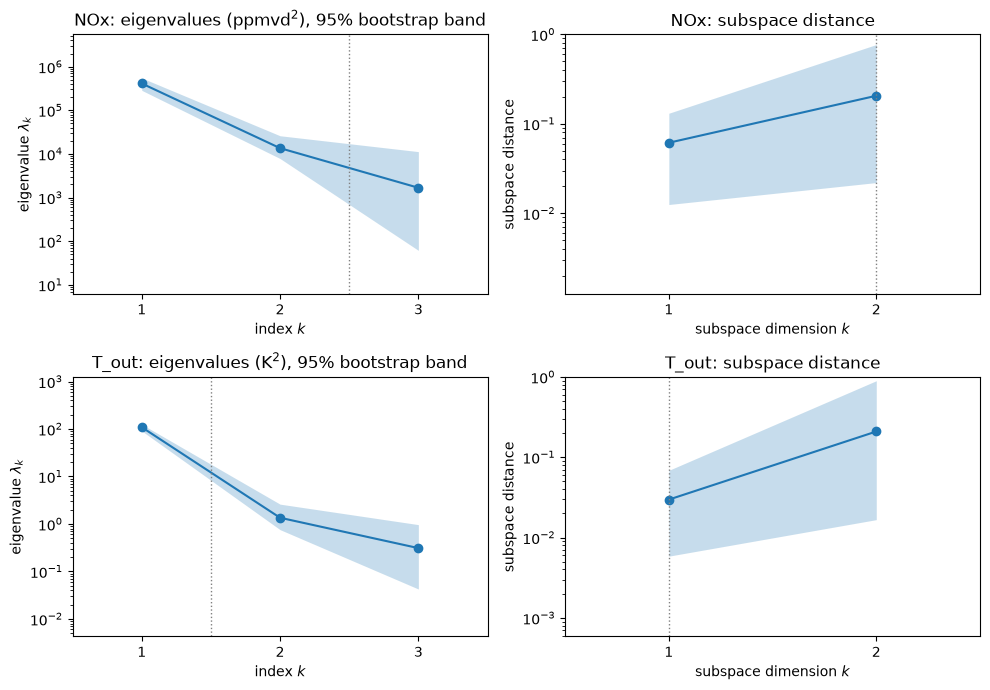

In [6]:
fig, axs = plt.subplots(2, 2, figsize=(10, 7))
for row, (q, (s, f, u)) in enumerate(SUBS.items()):
    ac.plotting.plot_eigenvalues(s, ax=axs[row, 0])
    axs[row, 0].set_title(f'{q}: eigenvalues ({u}$^2$), 95% bootstrap band')
    ac.plotting.plot_subspace_errors(s, ax=axs[row, 1])
    axs[row, 1].set_title(f'{q}: subspace distance')
fig.tight_layout()
plt.close(fig)
fig

For NO$_x$ the eigenvalues are $4.121 \times 10^5$, $1.357 \times 10^4$ and 1678 ppmvd$^2$ (ratios 30.4 and
8.1; shares of the trace 0.9643, 0.0318, 0.0039). The first gap is resolved by the bootstrap (intervals
$[2.865, 5.508] \times 10^5$ against $[7850, 2.61 \times 10^4]$), the second is not: the intervals of
$\lambda_2$ and $\lambda_3$ ($[61.68, 1.13 \times 10^4]$) overlap, and v1 warns that some replicates of $w_2$
are poorly aligned. The subspace distances show the same: for $k = 1$ the median is 0.059 (95 % band
[0.013, 0.131]), for the plane $k = 2$ it is 0.158 with a 95 % band of [0.022, 0.769], and 0.058 of the
replicates lie above 0.5. With $m = 3$ the plane is fixed by its normal $w_3$, and $w_3$ is not separated from
$w_2$, so the plane is only loosely determined. The quadratic behind this estimate fits NO$_x$ only moderately
(LOO $R^2$ 0.685). For $T_{out}$ the quadratic fits well (LOO $R^2$ 0.948) and the spectrum has one clear gap:
109, 1.351 and 0.31 K$^2$ (ratio 80.6, then 4.4), with median subspace distance 0.026 for $k = 1$ (95 % band
[0.006, 0.069]).

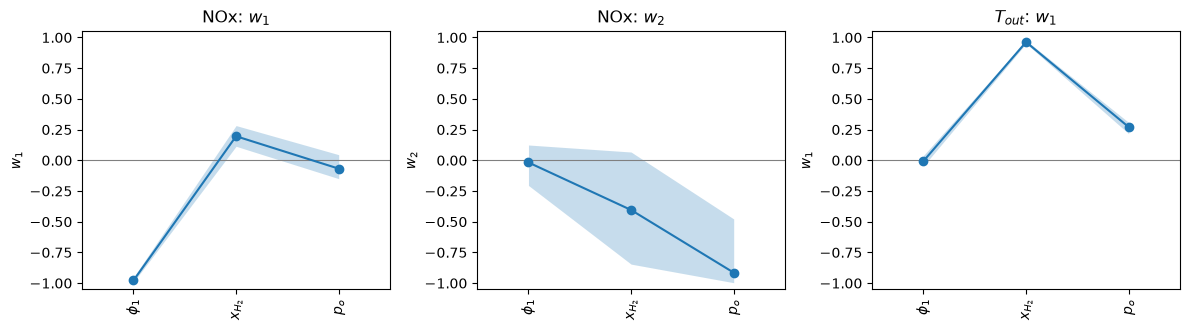

In [7]:
fig, axs = plt.subplots(1, 3, figsize=(12, 3.4))
for a, (s, j, title) in zip(axs, [(sub_nox, 0, 'NOx: $w_1$'), (sub_nox, 1, 'NOx: $w_2$'),
                                  (sub_t, 0, '$T_{out}$: $w_1$')]):
    ac.plotting.plot_eigenvectors(s, indices=[j], labels=LABELS, interval='percentile', ax=a)
    a.set_title(title)
fig.tight_layout()
plt.close(fig)
fig

For NO$_x$, $w_1$ = ($-0.978$, $+0.196$, $-0.068$) in ($\phi_1$, $x_{H_2}$, $p_o$): with the sign rule,
NO$_x$ increases along $y_1$, i.e. it is on average higher toward the near-stoichiometric end $\phi_1 = 1$
and, much less, at higher H$_2$ fractions. $w_2$ = ($-0.018$, $-0.404$, $-0.914$) is mainly pressure: NO$_x$ increases with $y_2$, i.e. it
decreases with pressure and, less, with the H$_2$ fraction; its bootstrap band is wide, as the overlapping
eigenvalue intervals lead one to expect. The left-out direction $w_3$ is mostly $x_{H_2}$
($+0.893$). For $T_{out}$, $w_1$ = ($-0.006$, $+0.963$, $+0.271$): the outlet temperature rises with the H$_2$
fraction and, less, with pressure, and hardly depends on $\phi_1$, consistent with the total air being set by
an energy balance for each case (p. 5) that misses the target more as the H$_2$ fraction grows.

In [8]:
# Cross-check 1: a cubic polynomial (20 coefficients) fitted to the same rows, its gradient averaged over
# the uniform box exactly (5-point Gauss-Legendre rule per input, exact for this polynomial degree).
t, wt = np.polynomial.legendre.leggauss(5)
ZQ = np.array(list(itertools.product(t, t, t)))
WQ = np.prod(np.array(list(itertools.product(wt, wt, wt))), axis=1) / 8.0
H = 1e-6


def cubic_check(Zfit, f):
    c = np.linalg.lstsq(basis(Zfit, 3), f, rcond=None)[0]
    G = np.column_stack([(basis(ZQ + H * e, 3) - basis(ZQ - H * e, 3)) @ c / (2 * H) for e in np.eye(m)])
    # G is the gradient in normalized coordinates; v1 takes physical points and gradients
    return ac.active_subspace(space=space, X=space.from_normalized(ZQ), grads=space.grads_to_physical(G),
                              quad_weights=WQ, n=1), loo_r2(basis(Zfit, 3), f)


def angle(a, b):
    return np.degrees(np.arccos(min(1.0, abs(float(a @ b)))))


lhs_rows = CASE <= 70
for q, (s, f, u) in SUBS.items():
    cub, r2 = cubic_check(Z, f)
    lam = cub.eigenvalues
    print(f'{q}: cubic fit LOO R2 {r2:.3f}; eigenvalues {", ".join(f"{v:.4g}" for v in lam)}; '
          f'ratios {lam[0] / lam[1]:.1f}, {lam[1] / lam[2]:.1f}; angle(w1 cubic, w1 QPHD) '
          f'{angle(cub.eigenvectors[:, 0], s.eigenvectors[:, 0]):.1f} deg')
    with warnings.catch_warnings():
        warnings.simplefilter('ignore', ac.ValidityWarning)
        lsub = ac.active_subspace(space=space, X=X[lhs_rows], f=f[lhs_rows], estimator='qphd', n=1)
    ll = lsub.eigenvalues
    print(f'   QPHD on the {lhs_rows.sum()} LHS cases only: ratios {ll[0] / ll[1]:.1f}, {ll[1] / ll[2]:.1f}; '
          f'angle(w1 LHS, w1 all) {angle(lsub.eigenvectors[:, 0], s.eigenvectors[:, 0]):.1f} deg; '
          f'w1 LHS = {", ".join(f"{v:+.3f}" for v in lsub.eigenvectors[:, 0] * np.sign(lsub.eigenvectors[:, 0] @ s.eigenvectors[:, 0]))}')

# Cross-check 3: NOx spans more than an order of magnitude; QPHD on log(NOx)
with warnings.catch_warnings():
    warnings.simplefilter('ignore', ac.ValidityWarning)
    slog = ac.active_subspace(space=space, X=X, f=np.log(NOX), estimator='qphd', n=1)
ll = slog.eigenvalues
wl = slog.eigenvectors[:, 0] * np.sign(slog.eigenvectors[:, 0] @ sub_nox.eigenvectors[:, 0])
print(f'log NOx: NOx max/min {NOX.max() / NOX.min():.1f}; quadratic LOO R2 {loo_r2(basis(Z, 2), np.log(NOX)):.3f}; '
      f'ratios {ll[0] / ll[1]:.1f}, {ll[1] / ll[2]:.1f}; w1 = {", ".join(f"{v:+.3f}" for v in wl)}; '
      f'angle(w1 log, w1 NOx) {angle(wl, sub_nox.eigenvectors[:, 0]):.1f} deg')

NOx: cubic fit LOO R2 0.896; eigenvalues 7.483e+05, 2.043e+04, 3126; ratios 36.6, 6.5; angle(w1 cubic, w1 QPHD) 6.6 deg
   QPHD on the 70 LHS cases only: ratios 37.5, 10.9; angle(w1 LHS, w1 all) 1.8 deg; w1 LHS = -0.976, +0.195, -0.100
T_out: cubic fit LOO R2 0.965; eigenvalues 154.7, 2.425, 1.83; ratios 63.8, 1.3; angle(w1 cubic, w1 QPHD) 2.5 deg
   QPHD on the 70 LHS cases only: ratios 20.3, 73.8; angle(w1 LHS, w1 all) 4.2 deg; w1 LHS = +0.062, +0.968, +0.244
log NOx: NOx max/min 42.9; quadratic LOO R2 0.657; ratios 17.2, 12.8; w1 = -0.980, +0.201, +0.006; angle(w1 log, w1 NOx) 4.2 deg


The cross-checks support $w_1$ of both QoIs. A cubic fit (LOO $R^2$ 0.896 for NO$_x$, 0.965 for
$T_{out}$), whose gradient is averaged exactly over the box, gives $w_1$ within 6.6° (NO$_x$) and 2.5°
($T_{out}$) of the QPHD direction, with first ratios 36.6 and 63.8. QPHD on the 70 Latin hypercube cases
alone, the only space-filling block, gives $w_1$ within 1.8° (NO$_x$) and 4.2° ($T_{out}$). NO$_x$ spans a
factor 42.9, and QPHD on $\log$ NO$_x$ gives $w_1$ = ($-0.980$, $+0.201$, $+0.006$), 4.2° from the NO$_x$
direction (ratios 17.2 and 12.8), although its quadratic fits worse (LOO $R^2$ 0.657), so the leading direction
does not depend on the scale of the QoI. The ratios after the first change between fits (NO$_x$: 8.1, 6.5 and
10.9; $T_{out}$: 4.4, 1.3 and 73.8): the second and third eigenvalues are not determined by these data beyond
their being much smaller than the first.

In [9]:
# How well does a polynomial in the first n active variables predict each QoI? (LOO R^2, exact)
print(f"{'QoI':6s} {'variables':22s}" + ''.join(f'  deg {d}' for d in range(1, 6)))
LOO = {}
for q, (s, f, u) in SUBS.items():
    for label, Y in [('y1', Z @ s.eigenvectors[:, :1]), ('y1, y2', Z @ s.eigenvectors[:, :2]),
                     ('all 3 inputs', Z)]:
        vals = [loo_r2(basis(Y, d), f) for d in range(1, 6)]
        LOO[(q, label)] = vals
        print(f'{q:6s} {label:22s}' + ''.join(f'  {v:5.3f}' for v in vals)
              + f'   best {max(vals):.3f} (degree {int(np.argmax(vals)) + 1})')
BEST = {key: int(np.argmax(v)) + 1 for key, v in LOO.items()}       # degree with the largest LOO R^2

# The same for NOx with the QPHD directions re-estimated without the left-out case (173 refits per row)
print('\nNOx, directions refitted in every fold (at the best degree of each row above):')
for n, deg in [(1, BEST[('NOx', 'y1')]), (2, BEST[('NOx', 'y1, y2')])]:
    pred = np.zeros(M)
    with warnings.catch_warnings():
        warnings.simplefilter('ignore', ac.ValidityWarning)
        for i in range(M):
            tr = np.arange(M) != i
            W = ac.active_subspace(space=space, X=X[tr], f=NOX[tr], estimator='qphd', n=n).eigenvectors[:, :n]
            c = np.linalg.lstsq(basis(Z[tr] @ W, deg), NOX[tr], rcond=None)[0]
            pred[i] = (basis(Z[i:i + 1] @ W, deg) @ c)[0]
    print(f'  n = {n}, degree {deg}: LOO R2 {1 - np.sum((NOX - pred)**2) / np.sum((NOX - NOX.mean())**2):.3f}')

QoI    variables               deg 1  deg 2  deg 3  deg 4  deg 5
NOx    y1                      0.147  0.616  0.726  0.719  0.660   best 0.726 (degree 3)
NOx    y1, y2                  0.193  0.707  0.868  0.884  0.905   best 0.905 (degree 5)
NOx    all 3 inputs            0.180  0.685  0.896  0.928  0.905   best 0.928 (degree 4)
T_out  y1                      0.887  0.941  0.959  0.959  0.958   best 0.959 (degree 3)
T_out  y1, y2                  0.885  0.949  0.966  0.964  0.946   best 0.966 (degree 3)
T_out  all 3 inputs            0.885  0.948  0.965  0.945  0.939   best 0.965 (degree 3)

NOx, directions refitted in every fold (at the best degree of each row above):
  n = 1, degree 3: LOO R2 0.695


  n = 2, degree 5: LOO R2 0.899


**Dimension.** The table gives the best LOO $R^2$ over degrees 1–5 for every set of variables. For $T_{out}$,
$n = 1$: the gap after $\lambda_1$ (80.6) is the only one, and the best polynomial in $y_1$ predicts as well
as the best in all three inputs (LOO $R^2$ 0.959 against 0.965, both cubic). For NO$_x$ the eigenvalues alone
would suggest $n = 1$ (the only gap the bootstrap resolves), but one active variable is not enough to predict
NO$_x$: the best polynomial in $y_1$ has LOO $R^2$ 0.726 (degree 3), in $(y_1, y_2)$ 0.905 (degree 5) and in
all three inputs 0.928 (degree 4). Refitting the directions in every fold, at the same degrees, gives 0.695 for
$n = 1$ and 0.899 for $n = 2$, so the gain does not come from choosing $W$ with the left-out case.
**NO$_x$ is analysed with $n = 2$** on this predictive evidence: the second direction is mostly pressure and
carries a real part of the variation (the sufficient summary plot shows it). The eigenvalues do not support
the plane as well: $\lambda_2/\lambda_3$ = 8.1 is not resolved by the bootstrap, and the plane's subspace
distance has a 95 % band of [0.022, 0.769]. With $m = 3$ this is a reduction by one dimension; the direction
left out is mostly $x_{H_2}$ ($w_3$ above, share of the trace 0.0039).

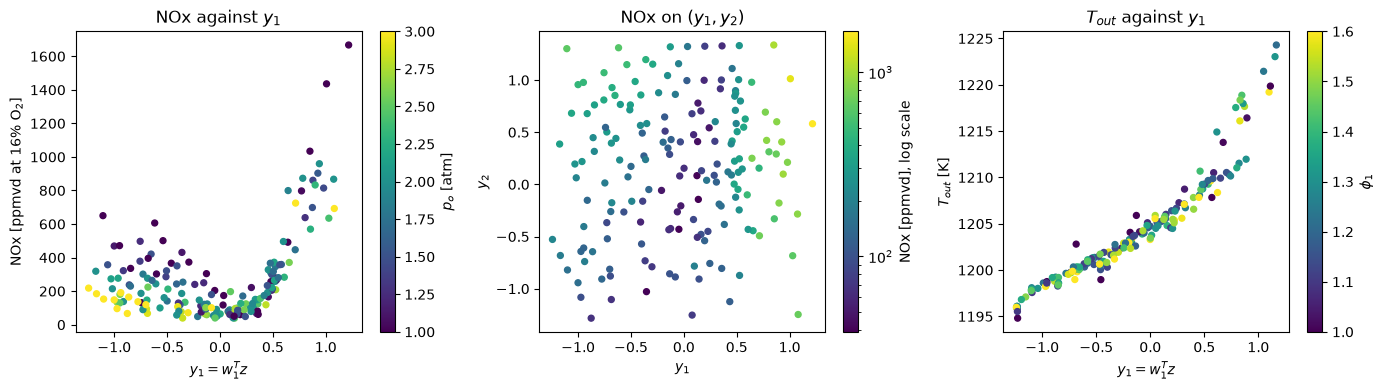

In [10]:
fig, axs = plt.subplots(1, 3, figsize=(14, 4))
y = Z @ sub_nox.eigenvectors
sc = axs[0].scatter(y[:, 0], NOX, c=X[:, 2] / 101325, cmap='viridis', s=18)
fig.colorbar(sc, ax=axs[0], label='$p_o$ [atm]')
axs[0].set_xlabel('$y_1 = w_1^T z$')
axs[0].set_ylabel('NOx [ppmvd at 16% O$_2$]')
axs[0].set_title('NOx against $y_1$')
sc = axs[1].scatter(y[:, 0], y[:, 1], c=NOX, cmap='viridis', s=18, norm=LogNorm())
fig.colorbar(sc, ax=axs[1], label='NOx [ppmvd], log scale')
axs[1].set_xlabel('$y_1$')
axs[1].set_ylabel('$y_2$')
axs[1].set_title('NOx on $(y_1, y_2)$')
yt = Z @ sub_t.eigenvectors[:, 0]
sc = axs[2].scatter(yt, TOUT, c=X[:, 0], cmap='viridis', s=18)
fig.colorbar(sc, ax=axs[2], label=r'$\phi_1$')
axs[2].set_xlabel('$y_1 = w_1^T z$')
axs[2].set_ylabel('$T_{out}$ [K]')
axs[2].set_title('$T_{out}$ against $y_1$')
fig.tight_layout()
plt.close(fig)
fig

In [11]:
# Numbers behind the description of the sufficient summary plots
low = np.argsort(NOX)[:10]
print(f'10 lowest-NOx cases ({NOX[low].min():.1f}-{NOX[low].max():.1f} ppmvd): y1 {y[low, 0].min():+.2f} to '
      f'{y[low, 0].max():+.2f}, phi1 {X[low, 0].min():.3f}-{X[low, 0].max():.3f} (y1 range of all cases '
      f'{y[:, 0].min():+.2f} to {y[:, 0].max():+.2f})')
hi = y[:, 0] > 0.5
print(f'y1 > 0.5: {hi.sum()} cases, phi1 {X[hi, 0].min():.3f}-{X[hi, 0].max():.3f}, NOx min {NOX[hi].min():.1f}, '
      f'median {np.median(NOX[hi]):.1f} ppmvd; y1 <= 0.5: median {np.median(NOX[~hi]):.1f} ppmvd')
rich = y[:, 0] < 0
p_atm = X[:, 2] / 101325
for lab, sel in [('p0 <= 1.5 atm', rich & (p_atm <= 1.5)), ('p0 >= 2.5 atm', rich & (p_atm >= 2.5))]:
    print(f'y1 < 0 and {lab}: {sel.sum()} cases, median NOx {np.median(NOX[sel]):.1f} ppmvd')
rk = lambda v: np.argsort(np.argsort(v))   # noqa: E731
print(f'y1 < 0: rank correlation of NOx with y2 {np.corrcoef(rk(NOX[rich]), rk(y[rich, 1]))[0, 1]:+.2f}, '
      f'with p0 {np.corrcoef(rk(NOX[rich]), rk(X[rich, 2]))[0, 1]:+.2f}')
Bt = basis(yt[:, None], 3)
res_t = TOUT - Bt @ np.linalg.lstsq(Bt, TOUT, rcond=None)[0]
print(f'T_out: rank correlation with its y1 {np.corrcoef(rk(TOUT), rk(yt))[0, 1]:+.3f}; rank correlation of the '
      f'residual of a cubic in y1 with phi1 {np.corrcoef(rk(res_t), rk(X[:, 0]))[0, 1]:+.2f}')

10 lowest-NOx cases (38.9-54.2 ppmvd): y1 -0.35 to +0.24, phi1 1.200-1.430 (y1 range of all cases -1.24 to +1.22)
y1 > 0.5: 35 cases, phi1 1.000-1.175, NOx min 208.6, median 569.6 ppmvd; y1 <= 0.5: median 146.8 ppmvd
y1 < 0 and p0 <= 1.5 atm: 28 cases, median NOx 343.2 ppmvd
y1 < 0 and p0 >= 2.5 atm: 26 cases, median NOx 113.7 ppmvd
y1 < 0: rank correlation of NOx with y2 +0.73, with p0 -0.57
T_out: rank correlation with its y1 +0.986; rank correlation of the residual of a cubic in y1 with phi1 -0.14


Left: NO$_x$ against $y_1$ is V-shaped. The 10 lowest-NO$_x$ cases (38.9–54.2 ppmvd) lie at $y_1$ = −0.35
to +0.24, in the middle of the range (−1.24 to +1.22), with $\phi_1$ = 1.200–1.430; the 35 cases with
$y_1 > 0.5$ have $\phi_1$ = 1.000–1.175 and median NO$_x$ 569.6 ppmvd (146.8 for the rest). On the rich side
($y_1 < 0$) the colour orders the spread: median NO$_x$ 343.2 ppmvd at $p_o \le$ 1.5 atm (28 cases) against
113.7 at $p_o \ge$ 2.5 atm (26 cases). Middle: on $(y_1, y_2)$, with a logarithmic colour scale, NO$_x$ rises
with $y_2$ across the rich half (rank correlation +0.73 for $y_1 < 0$, against −0.57 with $p_o$ alone) and is
high toward $\phi_1 = 1$ ($y_1 > 0.5$) for every $y_2$. Right: $T_{out}$ against its $y_1$ is nearly a single
curve (rank correlation +0.986) that steepens at high H$_2$ fractions; $\phi_1$ (colour) adds little (rank
correlation −0.14 between $\phi_1$ and the residual of a cubic in $y_1$).

In [12]:
DEG_NOX, DEG_T = BEST[('NOx', 'y1, y2')], BEST[('T_out', 'y1')]   # best degrees of the LOO table
sur_nox = ac.fit_surrogate(X=X, f=NOX, subspace=sub_nox, kind='poly', degree=DEG_NOX)
sur_t = ac.fit_surrogate(X=X, f=TOUT, subspace=sub_t, kind='poly', degree=DEG_T)
for q, sur, f in [(f'NOx (n = 2, degree {DEG_NOX})', sur_nox, NOX), (f'T_out (n = 1, degree {DEG_T})', sur_t, TOUT)]:
    resid = sur.residuals
    print(f'{q}: LOO R2 {sur.loo_r_squared:.3f}; in-sample RMS residual {np.sqrt(np.mean(resid**2)):.2f}; '
          f'sd of the QoI {f.std():.2f}')

NOx (n = 2, degree 5): LOO R2 0.905; in-sample RMS residual 57.13; sd of the QoI 255.00
T_out (n = 1, degree 3): LOO R2 0.959; in-sample RMS residual 1.13; sd of the QoI 5.78


The polynomial surrogates on the chosen active variables (`ac.fit_surrogate`, exact LOO residuals, at the
best degrees of the table above) have LOO $R^2$ 0.905 for NO$_x$ (degree 5 in $y_1, y_2$; RMS residual
57.13 ppmvd against a standard deviation of 255.00) and 0.959 for $T_{out}$ (degree 3 in $y_1$; RMS residual
1.13 K against 5.78 K).

## Comparison with the paper

The paper prints no active subspace or sensitivity index. Its Table 2 (p. 5) gives outlet NO$_x$ of the
C-type design at the 28 grid points that are cases 71–98 of the data, so it checks the outlet reduction.

In [13]:
# Table 2, p. 5: outlet NOx (ppmv, dry, 16 % O2) of the C-type design; keys (xH2, p0 in atm); phi1 order PHI
PHI = [1.00, 1.15, 1.20, 1.25, 1.30, 1.45, 1.60]
TABLE2_C = {(0.0, 1): [1033, 60, 79, 175, 304, 606, 650], (0.0, 2): [873, 78, 46, 91, 148, 277, 315],
            (0.3, 1): [1428, 267, 92, 57, 84, 368, 474], (0.3, 2): [828, 282, 94, 39, 62, 159, 210]}
print(f"{'xH2':>4s} {'p0':>4s} {'phi1':>5s} {'case':>5s} {'Table 2':>8s} {'here':>8s} {'here/paper':>10s}")
ratios = []
case_grid = []
for (xh, pa), vals in TABLE2_C.items():
    for ph, v in zip(PHI, vals):
        k = np.where((np.abs(XALL[:, 0] - ph) < 1e-9) & (np.abs(XALL[:, 1] - xh) < 1e-9)
                     & (np.abs(XALL[:, 2] - pa * 101325) < 1e-6))[0]
        assert len(k) == 1 and 71 <= case[k[0]] <= 98
        here = col['NOx'][k[0]]
        ratios.append(here / v)
        case_grid.append(case[k[0]])
        print(f'{xh:4.1f} {pa:4d} {ph:5.2f} {case[k[0]]:5d} {v:8d} {here:8.1f} {here / v:10.3f}')
ratios = np.array(ratios)
case_grid = np.array(case_grid)
dev = np.abs(ratios - 1)
print(f'\n28 cases: |here/paper - 1| median {np.median(dev):.3f}; within 3 %: {np.sum(dev < 0.03)}; '
      f'within 10 %: {np.sum(dev < 0.10)}; largest {dev.max():.3f}')
print(f'T_out over the 173 analysed cases: mean {TOUT.mean():.1f} K, range {TOUT.min():.1f}-{TOUT.max():.1f} K '
      '(target 1200 K, pp. 4-5)')
blk0 = dev[:14]
blk3 = dev[14:]
far = np.argsort(-blk3)[:4]
print(f'0 % H2: largest deviation {blk0.max():.3f} ({100 * blk0.max():.1f} %); within 1 %: {np.sum(blk0 < 0.01)} of 14')
print(f'30 % H2: four largest deviations {", ".join(f"{blk3[k]:.3f}" for k in far)} '
      f'({100 * blk3[far].min():.1f}-{100 * blk3[far].max():.1f} %, cases {", ".join(str(c) for c in sorted(case_grid[14:][far]))}); '
      f'largest of the other ten {np.delete(blk3, far).max():.3f} ({100 * np.delete(blk3, far).max():.1f} %)')

 xH2   p0  phi1  case  Table 2     here here/paper
 0.0    1  1.00    71     1033   1034.3      1.001
 0.0    1  1.15    72       60     61.4      1.024
 0.0    1  1.20    73       79     79.8      1.010
 0.0    1  1.25    74      175    173.9      0.994
 0.0    1  1.30    75      304    304.3      1.001
 0.0    1  1.45    76      606    606.2      1.000
 0.0    1  1.60    77      650    650.0      1.000
 0.0    2  1.00    85      873    872.9      1.000
 0.0    2  1.15    86       78     79.0      1.012
 0.0    2  1.20    87       46     45.6      0.992
 0.0    2  1.25    88       91     91.2      1.002
 0.0    2  1.30    89      148    146.7      0.992
 0.0    2  1.45    90      277    276.8      0.999
 0.0    2  1.60    91      315    318.6      1.012
 0.3    1  1.00    78     1428   1435.7      1.005
 0.3    1  1.15    79      267    262.2      0.982
 0.3    1  1.20    80       92     80.5      0.875
 0.3    1  1.25    81       57     59.8      1.050
 0.3    1  1.30    82       84 

At 0 % H$_2$ all 14 values agree within 2.4 % (largest deviation 0.024, case 72: 61.4 against 60 ppmvd), 10
of them within 1 %. At 30 % H$_2$ ten agree within 5.0 % and four differ by 12.5–39.7 %: cases 80 (80.5
against 92), 82 (117.4 against 84), 92 (959.6 against 828) and 93 (192.4 against 282). At $\phi_1$ = 1.00
Table 2 gives the same values for the B- and C-type designs in all four blocks, as it should: the C-type holes
bring the mixture to $\phi = 1$ (pp. 4–5), which a $\phi_1 = 1$ stage already is, so they add no air, and the B
type has no holes (pp. 2–3). Three of these shared entries agree with the deposit (1033, 873 and 1428 against
1034.3, 872.9 and 1435.7). The fourth, case 92 at 30 % H$_2$ and 2 bar, does not (828 against 959.6), and in
the same block 828 is printed again as the N$_2$O of the B type, where every other N$_2$O entry at
$\phi_1$ = 1.00 is 0, including that of the C type that B should match. That suggests a misplaced entry in this
block of Table 2; for cases 80, 82 and 93 the deposited runs and the tabulated ones may simply differ. Over the 28 cases the median
deviation is 0.011. The agreement at 0 % H$_2$ is the evidence that the outlet reduction (mass-flux
weighting, dry basis, 21 % reference O$_2$) is close to the one behind Table 2.

| quantity | paper (page) | this notebook |
|---|---|---|
| outlet NO$_x$, 0 % H$_2$, 14 grid cases | Table 2, p. 5 | all within 2.4 %, 10 within 1 % |
| outlet NO$_x$, 30 % H$_2$, 14 grid cases | Table 2, p. 5 | 10 within 5.0 %; 4 differ by 12.5–39.7 % |
| outlet N$_2$O | Table 2, p. 5 | not computable (not a deposited field) |
| outlet temperature | target 1200 K (pp. 4–5) | 1194.8–1224.3 K, mean 1204.1 K |
| pressure effect | "increasing pressure generally reduced emissions" (p. 4) | $w_2$ is mainly pressure; NO$_x$ decreases with $p_o$ along it |
| low-NO$_x$ region | identified (p. 6), not given numerically | minimum of NO$_x$ in the middle of the $y_1$ range; the 10 lowest cases have $\phi_1$ = 1.200–1.430 |
| active subspace, eigenvalues | not reported | NO$_x$: ratios 30.4, 8.1; $T_{out}$: 80.6, 4.4 |
| surrogate accuracy | not reported (PCE and POD–GPR models in refs. 30–31) | LOO $R^2$ 0.905 (NO$_x$, $n = 2$), 0.959 ($T_{out}$, $n = 1$) |

## References

- A. Piscopo, L. Giuntini, C. Novelli, W. De Paepe, A. Parente. A CFD dataset for supporting
  machine-learning-based models of hydrogen–ammonia combustion. *Machine Learning: Engineering* 2(1):010601,
  2026. [doi:10.1088/3049-4761/ae61b5](https://doi.org/10.1088/3049-4761/ae61b5)
- A. Piscopo, L. Giuntini, C. Novelli, W. De Paepe, A. Parente. A CFD dataset for supporting machine-learning-based models
  of hydrogen-ammonia combustion (Zenodo, v2.0, CC BY 4.0), 2026. [doi:10.5281/zenodo.19348021](https://doi.org/10.5281/zenodo.19348021)
- L. Giuntini, C. Novelli, M. M. Kamal, M. Cafiero, C. Galletti, A. Coussement, A. Parente.
  Continuously-staged NH$_3$ oxidation in a stagnation-point reverse-flow combustor for low NO$_x$ emissions.
  *Proceedings of the Combustion Institute* 40(1–4):105674, 2024.
  [doi:10.1016/j.proci.2024.105674](https://doi.org/10.1016/j.proci.2024.105674)
- K. P. Shrestha, L. Seidel, T. Zeuch, F. Mauss. Detailed kinetic mechanism for the oxidation of ammonia
  including the formation and reduction of nitrogen oxides. *Energy & Fuels* 32(10):10202–10217, 2018.
  [doi:10.1021/acs.energyfuels.8b01056](https://doi.org/10.1021/acs.energyfuels.8b01056)
- P. G. Constantine. *Active Subspaces: Emerging Ideas for Dimension Reduction in Parameter Studies*. SIAM,
  2015. [doi:10.1137/1.9781611973860](https://doi.org/10.1137/1.9781611973860)
- K.-C. Li. On principal Hessian directions for data visualization and dimension reduction: another
  application of Stein's lemma. *Journal of the American Statistical Association* 87(420):1025–1039, 1992.
  [doi:10.1080/01621459.1992.10476258](https://doi.org/10.1080/01621459.1992.10476258)

## Acknowledgments

From the paper (p. 9): A. Piscopo, W. De Paepe and A. Parente acknowledge the Fonds National de la Recherche
Scientifique (FRS-FNRS) for the Hydrogenate Project (T004222F); A. Parente and C. Novelli acknowledge the
European Union's Horizon Europe research and innovation program, grant agreement No 101072779; L. Giuntini
acknowledges SPF Finances (H2GridTwin project).

In [14]:
print(f'notebook run time: {time.perf_counter() - t_start:.0f} s')

notebook run time: 3 s
